### Code to numerically solve the 1d model for solvent concentration

This code is written for a fixed domain.


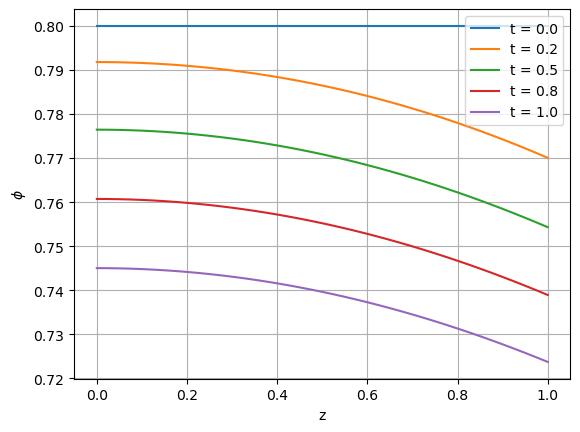

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# define physical parameters
Pe = 1
delta = 2
a = 2
phi_e = 0.5

# initial conditions
h_0 = 1
phi_0 = 0.8

# define diffusivity functions
def D(u):
    return (1-delta)*u**a + delta

def D_prime(u):
    return a*(1-delta)*u**(a-1)

def F(u, N, Pe, delta, a, phi_e, dx, D, D_prime):
    F = np.zeros(N+1) # preallocate array = size of system
    
    # derived ghost point expressions
    # 1st ghost point for first spatial derivative u_-1 = u_1
    u_ghost1 = u[1]
    u_ghost2 = u[N-1] - ((2*Pe*dx)/D(u[N]))*(1-u[N])*(u[N]- phi_e)
    
    # on substrate boundary
    F[0] = (1/Pe)* (D(u[0])*(u[1] - 2*u[0] +u_ghost1)/dx**2 + D_prime(u[0])*((u[1]-u_ghost1)/(2*dx))**2)
    
    # at free surface
    F[-1] = (1/Pe)* (D(u[-1])*(u_ghost2 - 2*u[-1] +u[-2])/dx**2 + D_prime(u[-1])*((u_ghost2 - u[-2])/(2*dx))**2)
    
    # interior grid points
    # for i in range(1, N):
        # F[i] = (1/Pe)* (D(u[i])*(u[i+1] - 2*u[i] +u[i-1])/dx**2 + D_prime(u[i])*((u[i+1] - u[i-1])/(2*dx))**2)
    F[1:N] = (1/Pe) * (D(u[1:N]) * (u[2:N+1] - 2*u[1:N] + u[0:N-1]) / dx**2+ D_prime(u[1:N]) * ((u[2:N+1] - u[0:N-1]) / (2*dx))**2)
    return F

def euler_method(F, tspan, u_0, Nt, N, Pe, delta, a, phi_e, dx, D, D_prime):
    t0, tf = tspan
    
    # time step and points
    dt = (tf - t0) / Nt
    t = np.linspace(t0, tf, Nt+1)
    
    # solution matrix
    u_sol = np.zeros((Nt+1, len(u_0)))
    
    # initial condition
    u_sol[0] = u_0
    
    # euler method
    for k in range(Nt):
        u_sol[k+1] = u_sol[k] + dt * F(u_sol[k], N, Pe, delta, a, phi_e, dx, D, D_prime)
    
    return t, u_sol


# spatial discretisation
dx = 0.025
N = round(h_0 / dx)
x = np.linspace(0, h_0, N + 1)

# time discretisation
tspan = [0, 1]

dt = 0.0001
Nt = round((tspan[1] - tspan[0]) / dt)

# initial condition
u_0 = np.full(N + 1, phi_0)

t, u_sol = euler_method(F, tspan, u_0, Nt, N, Pe, delta, a, phi_e, dx, D, D_prime)
                    
times_to_plot = [0, 0.25, 0.5, 0.75, 1]

for time in times_to_plot:
    k = np.argmin(np.abs(t - time))
    plt.plot(x, u_sol[k, :], label=f't = {t[k]:.1f}')

plt.xlabel('z')
plt.ylabel(r'$\phi$')
plt.legend()
plt.grid(True)
plt.show() 

Maximum conservation error: 0.06211690137730563


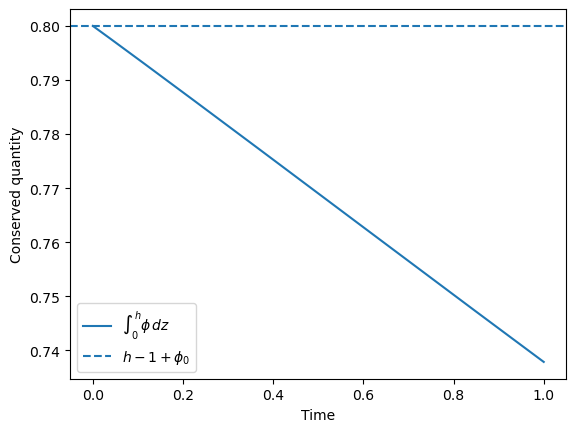

In [17]:
# calculate integral of phi over z at every time step
integral_phi = np.trapz(u_sol, x, axis=1)

# conserved quantity
expected = h_0 - 1 + phi_0

# error
error = integral_phi - expected

print("Maximum conservation error:", np.max(np.abs(error)))
plt.figure()
plt.plot(t, integral_phi, label=r'$\int_0^h \phi\,dz$')
plt.axhline(expected, linestyle='--', label=r'$h-1+\phi_0$')

plt.xlabel('Time')
plt.ylabel('Conserved quantity')
plt.legend()
plt.show()

Maximum absolute error = 7.59e-06


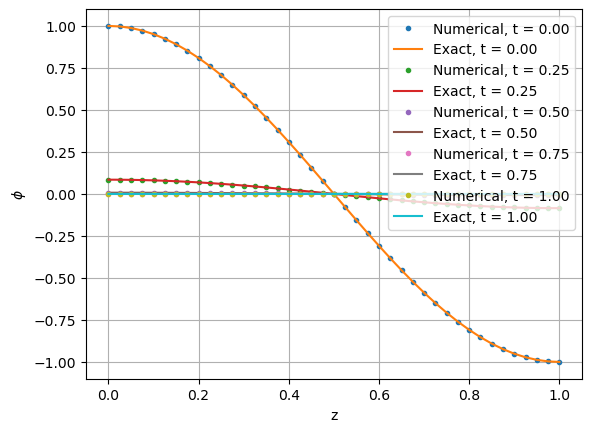

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# exact-solution test parameters
Pe_test = 1
D_test = 1
h_test = 1
A_test = 1
n_test = 1

# RHS: heat equation with zero-flux BCs
def F_test(u, N, Pe, D, dx):
    F = np.zeros(N+1)  # preallocate array = size of system
    # ghost points for zero flux (du/dz = 0) at both ends
    u_ghost1 = u[1]      # u_{-1}  = u_1
    u_ghost2 = u[N-1]    # u_{N+1} = u_{N-1}

    # on substrate boundary
    F[0] = (D/Pe) * (u[1] - 2*u[0] + u_ghost1) / dx**2

    # at free surface
    F[-1] = (D/Pe) * (u_ghost2 - 2*u[-1] + u[-2]) / dx**2

    # interior grid points
    F[1:N] = (D/Pe) * (u[2:N+1] - 2*u[1:N] + u[0:N-1]) / dx**2
    return F

# Forward Euler 
def euler_test(F, tspan, u_0, Nt, N, Pe, D, dx):
    dt = (tspan[1] - tspan[0]) / Nt
    t = np.linspace(*tspan, Nt + 1)
    u = np.zeros((Nt + 1, N + 1))
    u[0] = u_0
    for k in range(Nt):
        u[k+1] = u[k] + dt * F(u[k], N, Pe, D, dx)
    return t, u

# discretisation 
dx_test = 0.025
N_test = round(h_test / dx_test)
z_test = np.linspace(0, h_test, N_test + 1)
tspan_test = [0, 1]
dt_test = 0.0001
Nt_test = round((tspan_test[1] - tspan_test[0]) / dt_test)

# initial condition 
u_0_test = A_test * np.cos(n_test * np.pi * z_test / h_test)

# numerical solution 
t_test, u_test = euler_test(F_test, tspan_test, u_0_test, Nt_test, N_test, Pe_test, D_test, dx_test)

# exact solution 
Z_test, T_test = np.meshgrid(z_test, t_test)
u_exact_test = A_test * np.cos(n_test * np.pi * Z_test / h_test) * np.exp(-n_test**2 * np.pi**2 * T_test / (Pe_test * h_test**2))

# error 
error_test = np.abs(u_test - u_exact_test)
print(f"Maximum absolute error = {np.max(error_test):.2e}")

# numerical vs exact
for time in [0, 0.25, 0.5, 0.75, 1]:
    k = np.argmin(np.abs(t_test - time))
    plt.plot(z_test, u_test[k], 'o', ms=3, label=f'Numerical, t = {t_test[k]:.2f}')
    plt.plot(z_test, u_exact_test[k], '-', label=f'Exact, t = {t_test[k]:.2f}')

plt.xlabel('z'); plt.ylabel(r'$\phi$'); plt.legend(); plt.grid(True); plt.show()
